<a href="https://colab.research.google.com/github/KostantinDubnitskyi/Methodd/blob/main/%D0%9B%D0%A0_10(%D0%94%D1%83%D0%B1%D0%BD%D0%B8%D1%86%D1%8C%D0%BA%D0%B8%D0%B9_4_8).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Дубницький Костянтин   
**Група:** 8  
**Дата:** 25.11.26

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [ ]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
# Ваш код:
from tensorflow.keras.layers import Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras import layers, models
from tensorflow import keras
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report
import os

# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [ ]:
# Завантажте Fashion MNIST, визначте class_names.
# Виведіть форми x_train, y_train, x_test, y_test.
# Ваш код:
fashion_mnist = tf.keras.datasets.fashion_mnist
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print("x_train:", x_train.shape, "| y_train:", y_train.shape)
print("x_test:", x_test.shape, "| y_test:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train: (60000, 28, 28) | y_train: (60000,)
x_test: (10000, 28, 28) | y_test: (10000,)


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

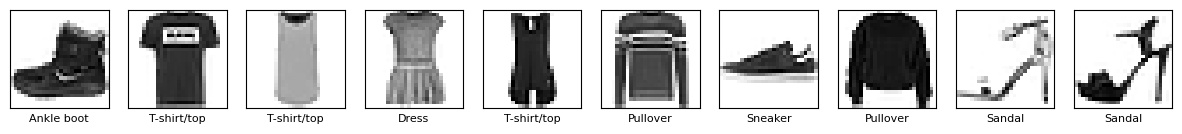

In [ ]:
# Побудуйте візуалізацію 10 зображень із підписами класів.
# Ваш код:
plt.figure(figsize=(15, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i], cmap=plt.cm.binary)
    plt.xlabel(class_names[y_train[i]], fontsize=8)
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [ ]:
# Нормалізуйте навчальні й тестові дані.
# Перевірте діапазони значень.
# Ваш код:
x_train = (x_train / 255.0).astype("float32")
x_test = (x_test / 255.0).astype("float32")

print("Тип даних:", x_train.dtype)
print("Діапазон x_train:", x_train.min(), "—", x_train.max())
print("Діапазон x_test:", x_test.min(), "—", x_test.max())

Тип даних: float32
Діапазон x_train: 0.0 — 1.0
Діапазон x_test: 0.0 — 1.0


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [ ]:
# Створіть і скомпілюйте модель.
# Ваш код:
model = models.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

Взяв два приховані шари на 256 і 64 нейрони: перший достатньо широкий, щоб вивчити залежності у 784 ознаках, а другий, вужчий, стискає ознаки перед виходом. Dropout 0.3 зменшує ризик перенавчання, але не сповільнює навчання надто сильно. Швидкість навчання 0.001 є стандартною для Adam: вона достатньо велика, щоб модель вчилась за розумну кількість епох, і достатньо мала, щоб навчання було стабільним. Коли покращення зупиняється, ReduceLROnPlateau додатково зменшує її для тонкого донавчання.

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [ ]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
# Ваш код:
cb = [
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1)
]

history = model.fit(
    x_train, y_train,
    epochs=50,
    batch_size=128,
    validation_split=0.1,
    callbacks=cb,
    verbose=1
)
print("Фактична кількість епох:", len(history.history['loss']))

Epoch 1/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.7661 - loss: 0.6639 - val_accuracy: 0.8390 - val_loss: 0.4268 - learning_rate: 0.0010
Epoch 2/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.8367 - loss: 0.4586 - val_accuracy: 0.8572 - val_loss: 0.3897 - learning_rate: 0.0010
Epoch 3/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.8531 - loss: 0.4131 - val_accuracy: 0.8683 - val_loss: 0.3597 - learning_rate: 0.0010
Epoch 4/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8604 - loss: 0.3897 - val_accuracy: 0.8717 - val_loss: 0.3502 - learning_rate: 0.0010
Epoch 5/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8664 - loss: 0.3715 - val_accuracy: 0.8713 - val_loss: 0.3449 - learning_rate: 0.0010
Epoch 6/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8706 - loss: 0.3547 - val_accuracy: 0.8807 - val_loss: 0.3328 - learning_rate: 0.0010
Epoch 7/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8769 - loss: 0.33

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [ ]:
# Виведіть підсумок архітектури моделі.
# Ваш код:
model.summary()
print("Кількість шарів:", len(model.layers))
print("Всього параметрів:", model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 654,176 (2.50 MB)

 Trainable params: 218,058 (851.79 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 436,118 (1.66 MB)

Кількість шарів: 6
Всього параметрів: 218058


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [ ]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
# Ваш код:
model.save('fashion_mnist_model.keras')

try:
    from google.colab import drive
    drive.mount('/content/drive')
    model.save('/content/drive/MyDrive/fashion_mnist_model.keras')
except Exception as e:
    print('Google Drive недоступний, модель збережено лише локально:', e)

Mounted at /content/drive


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

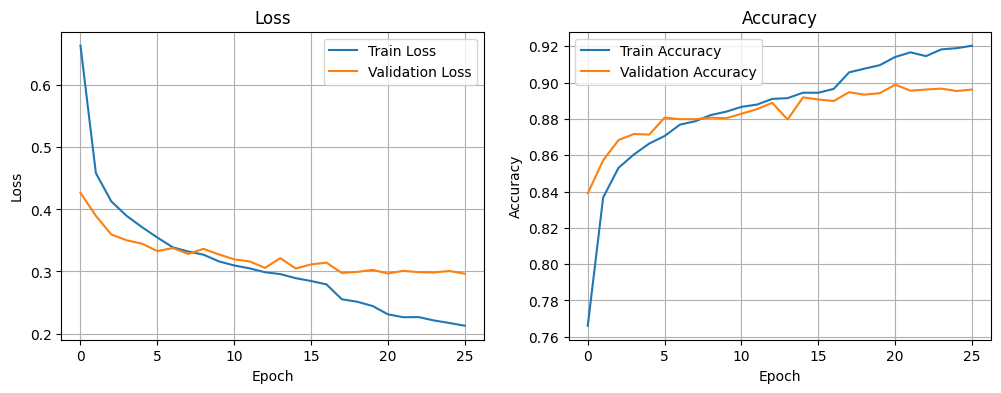

In [ ]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
# Ваш код:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid(True)
plt.legend()

plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [ ]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
# Ваш код:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
predictions = model.predict(x_test)

predicted_labels = np.argmax(predictions, axis=1)

print('Test accuracy:', test_acc)
print('Поріг 0.87:', 'виконано' if test_acc >= 0.87 else 'не виконано')

print(classification_report(y_test, predicted_labels, target_names=class_names))

313/313 - 1s - 3ms/step - accuracy: 0.8929 - loss: 0.3129
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Test accuracy: 0.8928999900817871
Поріг 0.87: виконано
              precision    recall  f1-score   support

 T-shirt/top       0.83      0.86      0.84      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.82      0.79      0.81      1000
       Dress       0.88      0.91      0.89      1000
        Coat       0.79      0.84      0.82      1000
      Sandal       0.98      0.97      0.98      1000
       Shirt       0.74      0.68      0.71      1000
     Sneaker       0.95      0.97      0.96      1000
         Bag       0.97      0.98      0.98      1000
  Ankle boot       0.97      0.96      0.97      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

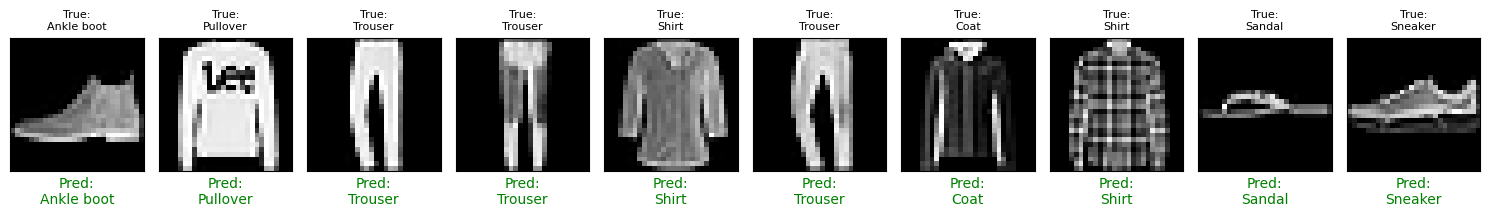

In [ ]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
# Ваш код:
plt.figure(figsize=(15, 3))

for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_test[i], cmap='gray')
    pred_label = class_names[predicted_labels[i]]
    true_label = class_names[y_test[i]]
    color = 'green' if predicted_labels[i] == y_test[i] else 'red'
    plt.xlabel(f"Pred:\n{pred_label}", color=color)
    plt.title(f"True:\n{true_label}", fontsize=8)

plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
Тестова accuracy моделі становить 0.8929, тобто вимогу не нижче 0.87 виконано. За classification_report найгірше модель розпізнає клас Shirt (F1 0.71, recall 0.68), далі Pullover (0.81), Coat (0.82) і T-shirt/top (0.84): це різні види верхнього одягу, схожі за формою. Найкращі результати в класів Trouser, Sandal і Bag (F1 0.98). Модель навчалась 26 епох, після чого EarlyStopping зупинив навчання і повернув найкращі ваги (val_accuracy близько 0.899 на 21-й епосі). На кривих навчання видно невелике перенавчання: навчальна точність (близько 0.92) вища за валідаційну (близько 0.90), а втрати на навчанні (близько 0.21) нижчі, ніж на валідації (близько 0.30).

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [ ]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
# Ваш код:
%pip install -q keras-tuner

In [ ]:
from keras_tuner.tuners import RandomSearch

### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [ ]:
# Підготуйте дані для добору гіперпараметрів і фінального тестування.
# Ваш код:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()
x_train = (x_train / 255.0).astype("float32")
x_test = (x_test / 255.0).astype("float32")

print("x_train:", x_train.shape, "| x_test:", x_test.shape)
print("Діапазон:", x_train.min(), "—", x_train.max())
print("Валідація: validation_split=0.1 від x_train; x_test, y_test у пошук не передаються.")

x_train: (60000, 28, 28) | x_test: (10000, 28, 28)
Діапазон: 0.0 — 1.0
Валідація: validation_split=0.1 від x_train; x_test, y_test у пошук не передаються.


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [ ]:
# Опишіть функцію build_model(hp).
# Задайте області пошуку гіперпараметрів.
# Ваш код:
def build_model(hp):
    model = keras.Sequential()
    model.add(keras.Input(shape=(28, 28)))
    model.add(Flatten())

    for i in range(hp.Int('num_layers', 1, 3)):
        model.add(Dense(units=hp.Int('units_' + str(i),
                                     min_value=32,
                                     max_value=512,
                                     step=32),
                        activation='relu',
                        kernel_regularizer=l2(0.001)))
        model.add(Dropout(0.2))

    model.add(Dense(10, activation='softmax'))

    model.compile(optimizer=keras.optimizers.Adam(
                      learning_rate=hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [ ]:
# Ініціалізуйте RandomSearch.
# Ваш код:
tuner = RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,
    executions_per_trial=1,
    directory='tuner_logs',
    project_name='fashion_mnist_classification',
    overwrite=True
)

### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [ ]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.
# Ваш код:
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6)

tuner.search(x_train, y_train, epochs=50, validation_split=0.1,
             callbacks=[early_stopping, reduce_lr])

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Найкращі гіперпараметри:", best_hp.values)

best_model = tuner.get_best_models(num_models=1)[0]
best_model.summary()

Trial 3 Complete [00h 01m 02s]
val_accuracy: 0.8653333187103271

Best val_accuracy So Far: 0.8653333187103271
Total elapsed time: 00h 05m 02s
Найкращі гіперпараметри: {'num_layers': 1, 'units_0': 32, 'learning_rate': 0.001, 'units_1': 320}


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
best_model = tuner.hypermodel.build(best_hp)

early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6)

history_tuned = best_model.fit(
    x_train, y_train,
    epochs=50,
    validation_split=0.1,
    callbacks=[early_stopping, reduce_lr]
)
print("Фактична кількість епох:", len(history_tuned.history['loss']))

Epoch 1/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7707 - loss: 0.7258 - val_accuracy: 0.8337 - val_loss: 0.5285 - learning_rate: 0.0010
Epoch 2/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.8253 - loss: 0.5597 - val_accuracy: 0.8470 - val_loss: 0.4955 - learning_rate: 0.0010
Epoch 3/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8334 - loss: 0.5308 - val_accuracy: 0.8537 - val_loss: 0.4735 - learning_rate: 0.0010
Epoch 4/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8354 - loss: 0.5167 - val_accuracy: 0.8507 - val_loss: 0.4647 - learning_rate: 0.0010
Epoch 5/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8378 - loss: 0.5100 - val_accuracy: 0.8507 - val_loss: 0.4730 - learning_rate: 0.0010
Epoch 6/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8413 - loss: 0.5019 - val_accuracy: 0.8578 - val_loss: 0.4502 - learning_rate: 0.0010
Epoch 7/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8422 - l

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8525 - loss: 0.4647
Test accuracy: 0.8525000214576721
Test loss: 0.4647037088871002


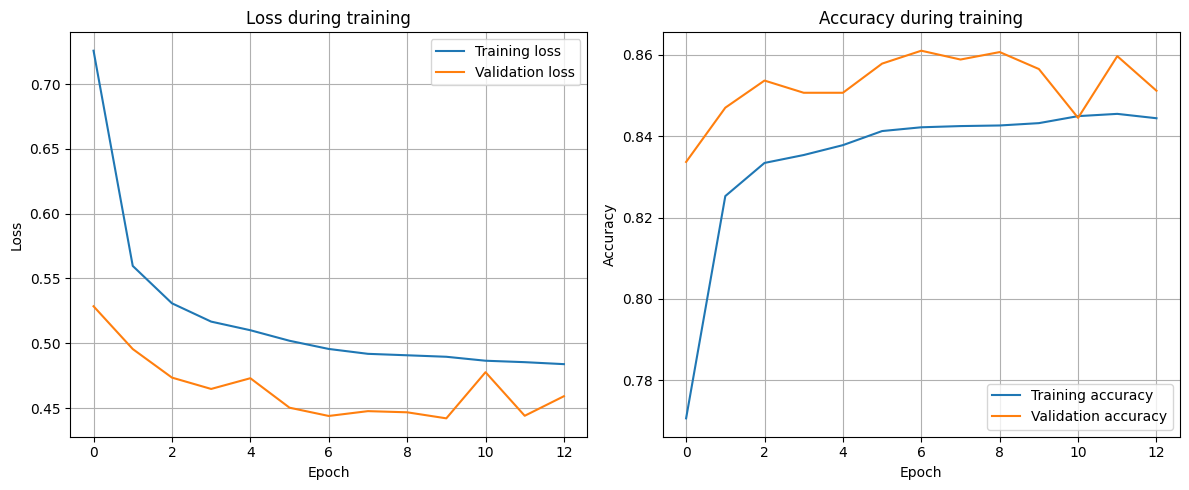

In [ ]:
# Оцініть найкращу модель та побудуйте графіки навчання.
# Ваш код:
test_loss_tuned, test_acc_tuned = best_model.evaluate(x_test, y_test)
print('Test accuracy:', test_acc_tuned)
print('Test loss:', test_loss_tuned)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_tuned.history['loss'], label='Training loss')
plt.plot(history_tuned.history['val_loss'], label='Validation loss')
plt.title('Loss during training')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_tuned.history['accuracy'], label='Training accuracy')
plt.plot(history_tuned.history['val_accuracy'], label='Validation accuracy')
plt.title('Accuracy during training')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів |2|2|
| Кількість нейронів | 256 і 64 | 384 і 288 |
| Швидкість навчання | 0.001 | 0.0001 |
| Точність на тестовій вибірці (accuracy) | 0.8929 | 0.8850 |
| Втрати на тестовій вибірці (loss) | 0.3129 | 0.4077 |
| Кількість епох навчання | 26 | 31 |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
1. У завданні 1 тестова accuracy становить 0.8929, що вище за поріг 0.87, тому вимогу виконано.
2. Оптимізація гіперпараметрів не покращила точність на тестовій вибірці: після Keras Tuner accuracy становить 0.8850, що на 0.0079 нижче, ніж у моделі із завдання 1 (0.8929). Різниця невелика, тож обидві моделі працюють приблизно однаково. Ймовірно, пошук із лише 3 спроб не встиг знайти кращу конфігурацію, ніж початкова. Втрати в моделі після Tuner також більші (0.4077 проти 0.3129), але частково це пояснюється тим, що loss у ній включає L2-штраф. На кривих цієї моделі навчальна точність (близько 0.91) трохи вища за валідаційну (близько 0.89), тобто є невелике перенавчання.
3. Найкращими гіперпараметрами виявились 2 приховані шари з 384 і 288 нейронами та швидкість навчання 0.0001, тобто модель більша (415 210 параметрів проти 218 058) і вчиться повільніше. Результат може відрізнятися між запусками, бо випадковий пошук щоразу обирає іншу комбінацію параметрів, а також випадкові початкові ваги, Dropout і перемішування даних.
4. Найскладніше класифікувати клас Shirt (F1 0.71), а також Pullover (0.81) і Coat (0.82).

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.